# Task 3 — Feature Engineering & Preprocessing Pipeline

**Dataset:** Breast Cancer Wisconsin Diagnostic dataset bundled with scikit-learn. This educational medical-diagnostics example has 569 rows and 30 numeric measurements. A derived `radius_band` category demonstrates one-hot encoding alongside numeric scaling.

**Goal:** Predict the dataset label with a reusable, leakage-free scikit-learn pipeline.

> Educational demonstration only. Do not use this model to diagnose real patients or guide clinical decisions.


## 1. Imports and load data

Dependencies: `pandas`, `numpy`, `scikit-learn`, and `matplotlib`. The dataset is bundled with scikit-learn; no separate download is needed.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, ConfusionMatrixDisplay, roc_auc_score
)
from sklearn.feature_selection import mutual_info_classif
from sklearn.inspection import permutation_importance

data = load_breast_cancer(as_frame=True)
X = data.data.copy()
y = data.target.copy()  # 0 = malignant, 1 = benign in this sklearn dataset

# Derived category solely to demonstrate categorical preprocessing.
X["radius_band"] = pd.cut(
    X["mean radius"], bins=[-np.inf, 12, 16, np.inf],
    labels=["small", "medium", "large"]
).astype("object")

print("Dataset shape:", X.shape)
print("Target counts (0=malignant, 1=benign):")
print(y.value_counts().sort_index())
display(X.head())


Dataset shape: (569, 31)
Target counts (0=malignant, 1=benign):
target
0    212
1    357
Name: count, dtype: int64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,radius_band
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,large
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,large
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,large
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,small
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,large


## 2. Data-quality checks

Check dimensions, missing values, duplicate rows, and class balance.

In [2]:
print("Rows, columns:", X.shape)
print("\nMissing values:")
display(X.isna().sum().sort_values(ascending=False).head(10))
print("Duplicate rows:", X.duplicated().sum())
print("\nTarget balance:")
display(y.map({0: "malignant", 1: "benign"}).value_counts())


Rows, columns: (569, 31)

Missing values:


mean radius               0
mean texture              0
mean perimeter            0
mean area                 0
mean smoothness           0
mean compactness          0
mean concavity            0
mean concave points       0
mean symmetry             0
mean fractal dimension    0
dtype: int64

Duplicate rows: 0

Target balance:


target
benign       357
malignant    212
Name: count, dtype: int64

## 3. Train/test split before preprocessing

Split first. Imputers, scaling, and encoding are fitted only on training data through the pipeline, preventing test-set leakage.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
numeric_features = X_train.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=["number"]).columns.tolist()
print("Training rows:", len(X_train), "| Test rows:", len(X_test))
print("Numeric features:", len(numeric_features))
print("Categorical features:", categorical_features)


Training rows: 455 | Test rows: 114
Numeric features: 30
Categorical features: ['radius_band']


## 4. Reusable preprocessing pipeline

Numeric columns use median imputation and standard scaling. Categorical columns use most-frequent imputation and one-hot encoding. `ColumnTransformer` applies the correct transformations.

In [4]:
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=3000, random_state=42))
])
model.fit(X_train, y_train)
print("Pipeline trained successfully.")


Pipeline trained successfully.


## 5. Evaluate on held-out test data

Label `0` is malignant and label `1` is benign in this dataset.

,Metric,Score
0,Accuracy,0.982
1,Precision (benign=1),0.986
2,Recall (benign=1),0.986
3,F1 (benign=1),0.986
4,ROC-AUC,0.996


               precision    recall  f1-score   support

malignant (0)       0.98      0.98      0.98        42
   benign (1)       0.99      0.99      0.99        72

     accuracy                           0.98       114
    macro avg       0.98      0.98      0.98       114
 weighted avg       0.98      0.98      0.98       114



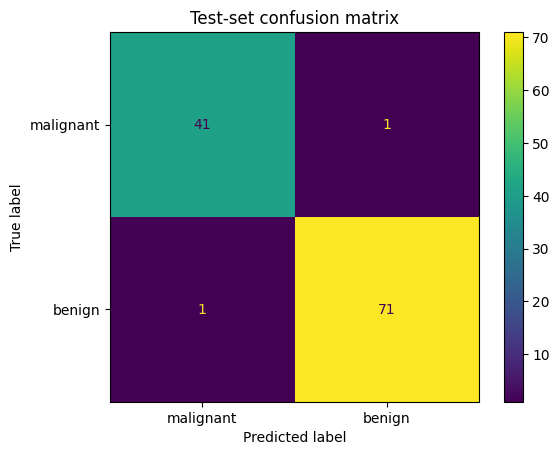

In [5]:
y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]
metrics = pd.DataFrame({
    "Metric": ["Accuracy", "Precision (benign=1)", "Recall (benign=1)", "F1 (benign=1)", "ROC-AUC"],
    "Score": [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred, zero_division=0),
        recall_score(y_test, y_pred, zero_division=0),
        f1_score(y_test, y_pred, zero_division=0),
        roc_auc_score(y_test, y_proba)
    ]
})
display(metrics.round(3))
print(classification_report(y_test, y_pred,
    target_names=["malignant (0)", "benign (1)"], zero_division=0))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=["malignant", "benign"]
)
plt.title("Test-set confusion matrix")
plt.show()


## 6. Feature ranking with mutual information

This exploratory ranking is calculated using training data only. Numeric variables are discretized into quantile bins for this simple mutual-information analysis. Importance is not causation.

,mutual_information
worst perimeter,0.481212
worst radius,0.461001
worst area,0.455918
worst concave points,0.446498
mean concave points,0.438247
mean perimeter,0.390504
mean area,0.381170
mean radius,0.378107
mean concavity,0.364699
area error,0.344320


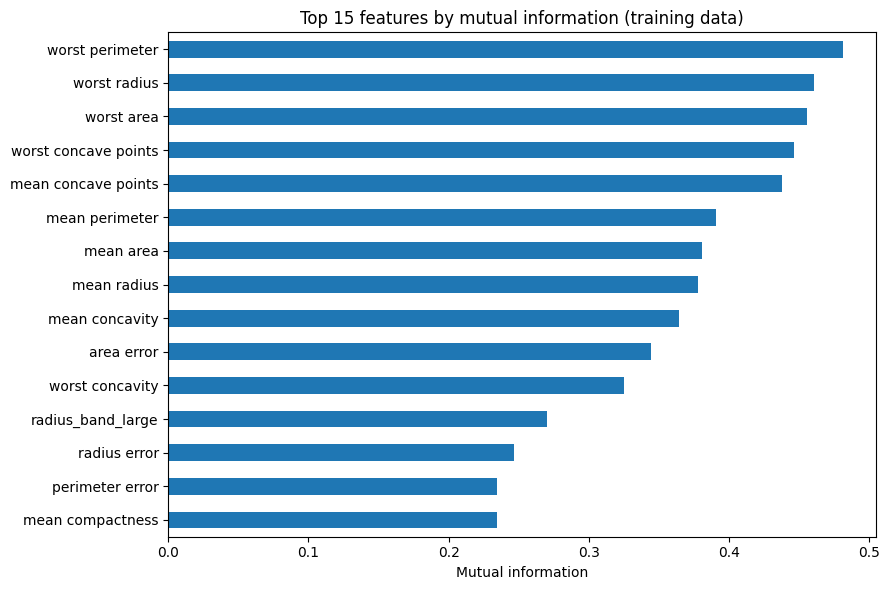

In [6]:
X_train_mi = X_train.copy()
for col in X_train_mi.select_dtypes(include=["number"]).columns:
    X_train_mi[col] = pd.qcut(
        X_train_mi[col].rank(method="first"),
        q=min(10, X_train_mi[col].nunique()),
        labels=False, duplicates="drop"
    )
X_train_mi = pd.get_dummies(X_train_mi, dummy_na=True)
mi_scores = mutual_info_classif(
    X_train_mi, y_train, discrete_features=True, random_state=42
)
mi = pd.Series(mi_scores, index=X_train_mi.columns).sort_values(ascending=False)
display(mi.head(15).rename("mutual_information").to_frame())
mi.head(15).sort_values().plot(kind="barh", figsize=(9, 6))
plt.title("Top 15 features by mutual information (training data)")
plt.xlabel("Mutual information")
plt.tight_layout()
plt.show()


## 7. Permutation importance

Shuffle each raw feature in the held-out set and measure the change in F1. Treat this as an explanatory check, not final independent validation.

,mean_f1_decrease
radius error,0.032856
worst texture,0.025384
area error,0.023114
worst area,0.022195
worst smoothness,0.021691
worst radius,0.019988
perimeter error,0.017926
mean concave points,0.016488
worst perimeter,0.014903
worst concave points,0.014843


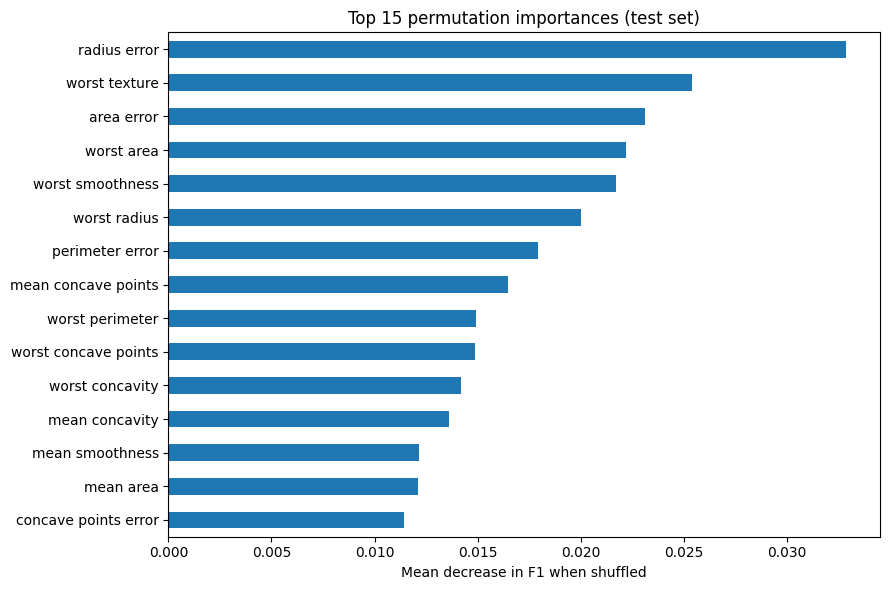

In [7]:
perm = permutation_importance(
    model, X_test, y_test, n_repeats=10,
    random_state=42, scoring="f1"
)
perm_importance = pd.Series(
    perm.importances_mean, index=X_test.columns
).sort_values(ascending=False)
display(perm_importance.head(15).rename("mean_f1_decrease").to_frame())
perm_importance.head(15).sort_values().plot(kind="barh", figsize=(9, 6))
plt.title("Top 15 permutation importances (test set)")
plt.xlabel("Mean decrease in F1 when shuffled")
plt.tight_layout()
plt.show()


## 8. Reuse the fitted pipeline

Provide a DataFrame with the same raw columns; the pipeline automatically applies imputation, scaling, and encoding.

In [8]:
example_record = X_test.iloc[[0]].copy()
prediction = model.predict(example_record)[0]
probabilities = model.predict_proba(example_record)[0]
print("Predicted class:", data.target_names[prediction])
print("Probability malignant:", round(float(probabilities[0]), 3))
print("Probability benign:", round(float(probabilities[1]), 3))
display(example_record)


Predicted class: malignant
Probability malignant: 1.0
Probability benign: 0.0


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,radius_band
256,19.55,28.77,133.6,1207.0,0.0926,0.2063,0.1784,0.1144,0.1893,0.06232,...,36.27,178.6,1926.0,0.1281,0.5329,0.4251,0.1941,0.2818,0.1005,large


## 9. Summary

1. Split the data before fitting preprocessing.
2. Use `ColumnTransformer` for type-specific preprocessing.
3. Keep preprocessing and estimator together in one `Pipeline`.
4. Use mutual information and permutation importance as exploratory tools.
5. Real medical applications require expert oversight, privacy safeguards, fairness checks, and external validation. This notebook is educational only.
